In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
from scipy.stats import linregress
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
import os
import tqdm
from tqdm import tqdm
import warnings
from scipy.optimize import differential_evolution

In [2]:
#while not recommended.. it will aid visually when looking at output, DONT RUN IF WARNINGS ARE DESIRED
# these arnings will NOT suppress errors as one can still traceback issues! 
##  however, it will suppress warnings detecvted while code is running, e.g. RunTimeError that does not result in an error rather it ends with unclear values (happens during fitting)

import warnings
warnings.filterwarnings("ignore")

# Define functions here

In [3]:
#define fitting functions
## currently, there are both a single and double terms exponential fit.
### some (all) currents display two decay phases, which can be charcaterized by the dbl_term function. if t1~~t2, then decay tau was hardly affected by the two phases..

def expFit(x, y0, A, t, x0):
    return y0 + A*np.exp(-(x - x0) / t)


def dblExpFit(x, y0, A1, x0, A2,t1, t2):
    return y0 + A1*np.exp(-(x - x0) / t1) + A2*np.exp(-(x - x0) / t2)

#def exp_decay(x, y_0, A_1, t_1, x_0):
#    return y_0 + A_1 * np.exp(-(x - x_0) / t_1)

In [4]:
##Here, define functions that help extrcating useful information.. really these are just functions for housekeeping stuff

def str_extrcat(self):
    st = 0
    for i in range(len(self)):
        if self[i] == '_':
            end = i
            break
    date = self[st:end]

    st = self.find('cell')
    i=st
    while i < len(self)-1:
        if self[i] == '_':
            end = i
            break
        i+=1
    cell = self[st:end]

    st = self.find('series')
    i=st
    while i < len(self)-1:
        if self[i] == '_':
            end = i
            break
        i+=1
    series = self[st:end]


    return cell, series, date






def find_match(cell, series, date, self):
    # self should be the array of waveform filenames
    
    for i in self:
        if cell in i and series in i and date in i:
            ffile = i
            break
    return ffile

def get_files(master_path):
    
    helpers = []
    waves = []
    for i in os.listdir(master_path):
        if 'csv' in i and 'wave' in i:
            waves.append(i)
        elif 'tsv' in i and 'helper' in i:
            helpers.append(i)
        elif 'csv' in i and 'helper' in i:  #might break in random off chance
            helpers.append(i)

    return helpers, waves


In [5]:
#######   here is the place for operations/functions =to deal with the actual data

def calculate_r_squared(ydata, f, xdata, popt):
    # though not the best, R2 will be used as a indexer of good/bad curve-fits

    residuals = ydata - f(xdata, *popt)
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((ydata - np.mean(ydata))**2)
    r2 = 1 - (ss_res / ss_tot)
    return r2

def get_riseSlope_dx(arr, plot=False):
    global model
    i = 1000
    while i >0:
        if arr[i] == np.median(arr):
            base_idx = i
            break
        i-=1
    if plot:
        plt.axhline(np.median(arr[:1000]), c='r')
        plt.axhline(np.min(arr[:1000]), c='r')
    try: 
        
        xs = np.array(list(range(base_idx, 1000+1)))/20000  #correct for real time units, does not affect graph
        ys = np.array(arr[base_idx:1000+1])
        model = linregress(xs, ys)

        riseSlope = model.slope
        dx = (1000-base_idx)/20000  #correct for sampling rate, at 1/20000 resolution

        if plot:
            #plt.plot(arr)
            plt.plot(xs*20000, model.intercept+model.slope*xs, c='r')
            
            #plt.title(riseSlope)
    except: # a clause to ensure the code keeps running... sometimes base_idx cannot be IDd due to noise
        dx = np.nan
        riseSlope = np.nan  

    return riseSlope, dx

def rmse(ydata, yfit):
    #root-mean squared error
    return np.sqrt(np.mean((ydata - yfit) ** 2))

def error_ratio(ydata, yfit):
    #should give a value that is sort of indicative of fit goodness..
    #    ER<1  --> better than mean
    #    ER = .5 --> ok
    #    ER < .1 --> very good
    return  rmse(ydata, yfit)/np.std(ydata)  #generate a ratio between the model error and the true error

def adjRsq(ydata, yfit, param_num = 6):
    #param_num: number of parameters in the model (dblExp = 6), used to penalize R2
    residuals = ydata - yfit
    sse = np.sum(residuals**2)
    sst = np.sum((ydata - np.mean(ydata))**2)
    r2 = 1-(sse/sst)
    n = len(ydata) #to help penalize based on param_num
    return 1 - (((1 - r2) * (n - 1)) / (n - param_num - 1))

def plot_sigNfit(self, row=0, extra=None):
    y = self.iloc[row].raw_sig
    yp = self.iloc[row].fit_sig
    xs = np.array(list(range(len(y))))/20000
    plt.plot(xs, y, c='b', label='raw signal')
    plt.plot(xs, yp, c='r', label='fitted line')
    plt.title(str(self.iloc[row].r2)+';        row '+str(row)+';  orient vibe: '+extra)
    plt.legend()
    plt.show()
    return


# Main code

In [ ]:




do_the_double = True   #set True if dblExponential is desired (doubleExp will provide slow and fast tau given the fitting function)
pflag=False   #boolean flag to limit plotting outputs (RAM/visual intensive.. plus, processing 1000s will yield 1000s of plots....)
check_min_pos = True  #this offers an additional step to ensure that the curve fit is performed starting from the peak..

use_evolution_estimate = True  #this boolean flag will trigger the use of differential-evolution estimation of fitting parameters!
                               #currently, evolution will be reserved for double-epponential fitting
evol_plot = False  #set to True for plotting

master_path = r'M:\HK patchview data\E2'  #set the path where helper and wave files exist

helpers, waves = get_files(master_path)  #run get_files function to loop through later


dfs = []   #initialize list to store tmp dfs
k = 0
for helper in helpers:  #loop through the helper files


    cell, series, date = str_extrcat(helper)  #extract relevant information for string search and annotation in dfs


    #if any(cell in s for s in done) and any(series in s for s in done) and any(date in s for s in done):
    #    print('skipping '+date+'_'+cell+'_'+series)
    #    continue


    try: 
        wave = find_match(cell, series, date, waves)  #finds the match of the current helper file
    except:
        print('skipping '+helper+'; there was no matching waveforms file. CHECK THAT THIS IS TRUE IN THE master_path')
        continue

    #tmp_help = pd.read_csv(os.path.join(master_path, helper), sep='\t') #read paired files  FOR TSV FILES
    tmp_help = pd.read_csv(os.path.join(master_path, helper)) #read paired files
    wave_tmp = pd.read_csv(os.path.join(master_path, wave))
    #wave_tmp = wave_tmp.drop(columns=['Time', 'Unnamed: 0'])

    ins = []
    for i in range(len(wave_tmp.columns)): #take care of extra columns that are not "Event"s
        if 'Event' in wave_tmp.columns[i]:
            ins.append(True)
        else:
            ins.append(False)
    wave_tmp = wave_tmp.loc[:, ins]
    wave_tmp = wave_tmp.T

    
    try:
        wave_tmp['inUse'] = np.array(tmp_help['InUse'])
    except:
        sub = len(tmp_help) - len(wave_tmp)
        wave_tmp['inUse'] = np.array(tmp_help['InUse'])[:-sub]
    wave_tmp = wave_tmp[wave_tmp.inUse==True].reset_index(drop=True)

    self2d = np.array(wave_tmp.drop(columns=['inUse']).T)

    ################### main analysis part #######################
    taus = []
    r2s = []
    amps = []
    rslopes = []
    dxs = []
    events = []
    vibes = []
    fast_taus = []
    slow_taus = []
    raw_sig = []
    fitted_sig = []
    adjR2s = []   
    rmse_ratios = []
    full_sig = []


    subi = date+'_'+cell+'_'+series
    for i in tqdm(range(self2d.shape[1]), 'processing '+subi+'; event '+str(i+1)+'/'+str(self2d.shape[1])):  #tqdm_it

        arr = self2d[:,i]
        if pflag:
            plt.plot(arr)

        #tarr = arr[np.argmin(arr):np.argmin(arr)+2000]  #this is unnecessary.. in a sense.. the peak should always be at 1000 if extrcated properly from PatchView.. 
        tarr = arr[1000:3000]
        if pflag:
            plt.plot(np.array(list(range(len(tarr))))+1000, tarr, c='g')

        xs = np.array(list(range(len(tarr))))  #BFC
        ys = np.array(tarr)

        if check_min_pos:
            if np.argmin(ys) !=0:
                if np.argmin(ys)-0>100:
                    continue
                else:
                    ys = ys[np.argmin(ys):]
                    xs = np.array(list(range(len(ys))))

        tau = -1  #set to an initial negative value as a ground-nought of what the value is KNOWN NOT TO BE
        r2 = -1  #same idea as tau above
        fast_tau = -1 #initialize to 'bad' value (negative time should always be filtered out..)
        slow_tau = -1

        #################  FITTING PORTION START  ################## 
        #should put in its own function.. though tracebacks may be annoying, so left here more verbose and easier to track/repeat errors (plus no dealing with globals..)

        #nested try/excerpt trials will try to get the fit in a somewhat strict manner, what changes is the freedom to perform additional fitting-estimate steps
        # if all fails, tau = np.nan
        if use_evolution_estimate:


            meanie = ys
            nxs = np.array(list(range(len(meanie))))/20000
            if evol_plot:
                plt.plot(nxs, meanie, c='b', alpha=.3)
                plt.plot(nxs[1000:], meanie[1000:], c='b')


            #fit_xs = nxs[1000:]
            #fit_data = meanie[1000:]
            

            
            hk_min = np.argmin(meanie)
            fit_xs = nxs[hk_min:]
            fit_data = meanie[hk_min:]


            xData = fit_xs
            yData = fit_data

            def sumOfSquaredError(parameterTuple):
                warnings.filterwarnings("ignore") # do not print warnings by genetic algorithm
                return np.sum((yData - dblExpFit(xData, *parameterTuple)) ** 2)

            def generate_Initial_Parameters():
                # min and max used for bounds
                # min and max used for bounds
                maxX = max(xData)
                minX = min(xData)
                maxY = max(yData)
                minY = min(yData)
                maxXY = max(maxX, maxY)

                parameterBounds = []
                parameterBounds.append([-maxXY, maxXY]) # seach bounds for a
                parameterBounds.append([-maxXY, maxXY]) # seach bounds for b
                parameterBounds.append([-maxXY, maxXY]) # seach bounds for c
                parameterBounds.append([-maxXY, maxXY]) # seach bounds for c
                parameterBounds.append([-maxXY, maxXY]) # seach bounds for c
                parameterBounds.append([-maxXY, maxXY]) # seach bounds for c



                # "seed" the numpy random number generator for repeatable results
                result = differential_evolution(sumOfSquaredError, parameterBounds, seed=3)
                return result.x


            # generate initial parameter values
            initialParameters = generate_Initial_Parameters()

            # curve fit the test data
            try:
                fittedParameters, niepewnosci = curve_fit(dblExpFit, xData, yData, initialParameters)
                vibe='good'
            except:
                try:
                    fittedParameters, niepewnosci = curve_fit(dblExpFit, xData, yData, initialParameters, 'dogbox', max_nfev=100000)
                    vibe='bad'
                except:
                    vibe='bad'
                    continue

            y0, A1, x0, A2,t1, t2 = fittedParameters

            y_fit = dblExpFit(xData, y0, A1, x0, A2,t1, t2)

            p0=[-3.95236374e-05,  4.25532270e-01, -6.62976889e+01, -4.25507029e-01, 9.84299868e+01,  9.84120365e+01]  #now optimized
            popt, pcov = curve_fit(dblExpFit, fit_xs, fit_data,p0=p0, method = 'dogbox', max_nfev=100000)
            if evol_plot:
                plt.plot(fit_xs, dblExpFit(fit_xs, *popt), c='r', label='double_expFit, NO evolution')

                plt.plot(fit_xs, y_fit, c='g', label='double_expFit WITH evolution')
                plt.legend()
            fast_tau = t1
            slow_tau = t2
            r2 = r2_score(yData, y_fit)
            ratio = error_ratio(yData, y_fit)
            adjr2 = adjRsq(yData, y_fit, param_num = 6)




        else:
            if do_the_double:  #if passed (i.e. True), then try doubleExp fit
                try: 
                    #init p0 values for the dblExp were derived based on an averaged trace/peak
                    #the _init_ paramters, p0, of the curve fit were obtained in the past as rather good estmates based on a fit of multiple waves (sizes shapes, its a ghenerally good place to start)
                    popt, pcov = curve_fit(dblExpFit, xs, ys, method = 'dogbox', p0=[-1.19496958e-11, -5.84738207e-11, -3.90354628e+01 , -3.90354628e+01, 1.07374313e+02, 1.07374313e+02], max_nfev=5000)
                    if pflag:
                        plt.plot(xs+1000, dblExpFit(xs, *popt), c='r', label='double_expFit')
                    fast_tau = popt[4]
                    slow_tau = popt[5]
                    vibe = 'good'
                    #r2 = calculate_r_squared(ys, expFit, xs, popt)
                except:
                    try: 
                        #the _init_ paramters, p0, of the curve fit were obtained in the past as rather good estmates based on a fit of multiple waves (sizes shapes, its a ghenerally good place to start)
                        print('optimal fit not reached, increasing number of iterations..')
                        popt, pcov = curve_fit(dblExpFit, xs, ys, method = 'dogbox', p0=[-1.19496958e-11, -5.84738207e-11, -3.90354628e+01 , -3.90354628e+01, 1.07374313e+02, 1.07374313e+02], max_nfev=10000)
                        if pflag:
                            plt.plot(xs+1000, dblExpFit(xs, *popt), c='r', label='double_expFit')
                        #r2 = calculate_r_squared(ys, expFit, xs, popt)
                        fast_tau = popt[4]
                        slow_tau = popt[5]
                        vibe='bad'
                    except:
                        tau = np.nan

            else:
                try: 
                    #the _init_ paramters, p0, of the curve fit were obtained in the past as rather good estmates based on a fit of multiple waves (sizes shapes, its a ghenerally good place to start)
                    popt, pcov = curve_fit(expFit, xs, ys, method = 'dogbox', p0=[-1.19496958e-11, -5.84738207e-11,  1.07374313e+02, -3.90354628e+01], max_nfev=5000)
                    if pflag:
                        plt.plot(xs+1000, expFit(xs, *popt), c='r', label='single_expFit')
                    tau = popt[2]
                    vibe = 'good'
                    #r2 = calculate_r_squared(ys, expFit, xs, popt)
                except:
                    try: 
                        #the _init_ paramters, p0, of the curve fit were obtained in the past as rather good estmates based on a fit of multiple waves (sizes shapes, its a ghenerally good place to start)
                        print('optimal fit not reached, increasing number of iterations..')
                        popt, pcov = curve_fit(expFit, xs, ys, method = 'dogbox', p0=[-1.19496958e-11, -5.84738207e-11,  1.07374313e+02, -3.90354628e+01], max_nfev=10000)
                        if pflag:
                            plt.plot(xs+1000, expFit(xs, *popt), c='r', label='single_expFit')
                        #r2 = calculate_r_squared(ys, expFit, xs, popt)
                        tau = popt[2]
                        vibe='bad'
                    except:
                        tau = np.nan
            if do_the_double:
                y_pred = dblExpFit(xs, *popt)
            else:
                y_pred = expFit(xs, *popt)
            r2 = r2_score(ys, y_pred)

        #################  FITTING PORTION END  ################## 

        amplitude = abs(np.min(arr[:950]) - np.median(arr[:500]))*10e12  #set to pA units!

        

        riseSlope, dx = get_riseSlope_dx(arr, plot=pflag)

        vibes.append(vibe)

        if do_the_double:  #clause do deal with dblExp vs single exp
            fast_taus.append(fast_tau)
            slow_taus.append(slow_tau)
        else:
            taus.append(tau)


        adjR2s.append(adjr2)    
        rmse_ratios.append(ratio)
        r2s.append(r2)
        amps.append(amplitude)
        rslopes.append(riseSlope)
        dxs.append(dx*1000)

        yData, y_fit
        raw_sig.append(yData)
        fitted_sig.append(y_fit)
        full_sig.append(arr)

        events.append('peak'+str(i))
        if pflag:
            plt.title('peak'+str(i))
            plt.show()

    tmp = pd.DataFrame()
    if do_the_double:
        tmp['fast_tau'] = fast_taus
        tmp['slow_tau'] = slow_taus
    else:
        tmp['tau'] = taus
        
    tmp['r2'] = r2s
    tmp['amplitude(pA)'] = amps
    tmp['riseSlope'] = rslopes
    tmp['riseTime_full(ms)'] = dxs  #this is the time between the peak and the median of the pre-peak baseline
    tmp['peak_id'] = events
    tmp['cell'] = cell
    tmp['series']=series
    tmp['date'] = date
    tmp['vibes'] = vibes
    tmp['raw_sig'] = raw_sig
    tmp['fit_sig'] = fitted_sig
    tmp['adjR2'] = adjR2s 
    tmp['rmse_ratio'] = rmse_ratios
    tmp['full_sig'] = full_sig

    dfs.append(tmp)
    print('processed file '+str(k+1)+'/'+str(len(helpers)))
    k+=1


processing 3-12-20_cell1_seriesA; event 225/146: 100%|██████████| 146/146 [18:20<00:00,  7.54s/it]


processed file 1/48


processing 3-12-20_cell1_seriesB; event 325/118: 100%|██████████| 118/118 [15:37<00:00,  7.94s/it]


processed file 2/48


processing 3-12-20_cell1_seriesC; event 294/76: 100%|██████████| 76/76 [09:51<00:00,  7.79s/it]


...

processed file 46/48


processing 2-24-21_cell3_seriesC; event 390/232: 100%|██████████| 232/232 [08:58<00:00,  2.32s/it]


processed file 47/48


processing 2-24-21_cell3_seriesD; event 446/181: 100%|██████████| 181/181 [06:59<00:00,  2.32s/it]

processed file 48/48


In [2]:
#adf.to_pickle(r'Z:\allSofar_evolutionWsignals.pkl')
adf = pd.read_pickle(r'C:\Users\15204\Downloads\allSofar_evolutionWsignals.pkl')

In [4]:
check = []

for i in tqdm(range(len(adf))):
    arr = adf.iloc[i].fit_sig
    if np.argmin(arr) < np.argmax(arr):
        check.append('good')
    else:
        check.append('bad')
adf['dir_check'] = check

100%|██████████| 15404/15404 [00:01<00:00, 13300.25it/s]


In [5]:
amps = []

for i in tqdm(range(len(adf))):
    arr = adf.iloc[i].raw_sig
    amps.append(np.max(arr)-np.min(arr))
adf['ampi'] = np.array(amps)*10e11




100%|██████████| 15404/15404 [00:01<00:00, 13592.40it/s]


In [6]:
combi = []
for i in tqdm(range(len(adf))):
    combi.append(adf.iloc[i].date+'_'+adf.iloc[i].cell+'_'+adf.iloc[i].series)
adf['combo'] = combi
adf.iloc[:2]

100%|██████████| 15404/15404 [00:02<00:00, 5672.62it/s]


,fast_tau,slow_tau,r2,amplitude(pA),riseSlope,riseTime_full(ms),peak_id,cell,series,date,vibes,raw_sig,fit_sig,adjR2,rmse_ratio,dir_check,ampi,combo
0,0.020167,0.014899,0.106904,27.428357,-3.870580e-10,1.8,peak3,cell1,series6,1-21-25,good,"[-3.0794564415644974e-11, -3.054521571592315e-...","[-2.997922561217297e-11, -2.99819175289937e-11...",0.101402,0.945038,bad,4.488277,1-21-25_cell1_series6
1,0.001352,0.001310,0.004977,21.818011,-4.294668e-10,4.7,peak6,cell1,series6,1-21-25,good,"[-3.0669890065784056e-11, -3.0732227240714515e...","[-3.0122330066310814e-11, -3.0164088436193576e...",-0.001054,0.997508,bad,4.238928,1-21-25_cell1_series6


In [7]:
# make a flag-check to dertermine the orientation of the fit (e.g. general downward or upward trned, where only upward is the correct decision..)

def orient_flag_check(sig):

    maxix = np.argmax(sig)
    minix = np.argmin(sig)

    if minix < maxix:
        flag = 'good'
    elif minix > maxix:
        flag = 'bad'
    elif minix == maxix:
        flag = 'bad'
    else:
        flag = 'undetermined, flag-check failed'
    return flag


orient_flag = []
for i in tqdm(range(len(adf))):
    orient_flag.append(orient_flag_check(adf.iloc[i].fit_sig))
adf['orient_flag'] = orient_flag



100%|██████████| 15404/15404 [00:00<00:00, 15879.44it/s]


In [9]:
ft = []
st = []
for i in tqdm(range(len(adf))):
    ft.append(adf.iloc[i].fast_tau*1000)
    st.append(adf.iloc[i].slow_tau*1000)
adf['slow_tau(ms)'] = st
adf['fast_tau(ms)'] = ft

100%|██████████| 15404/15404 [00:01<00:00, 9008.71it/s]


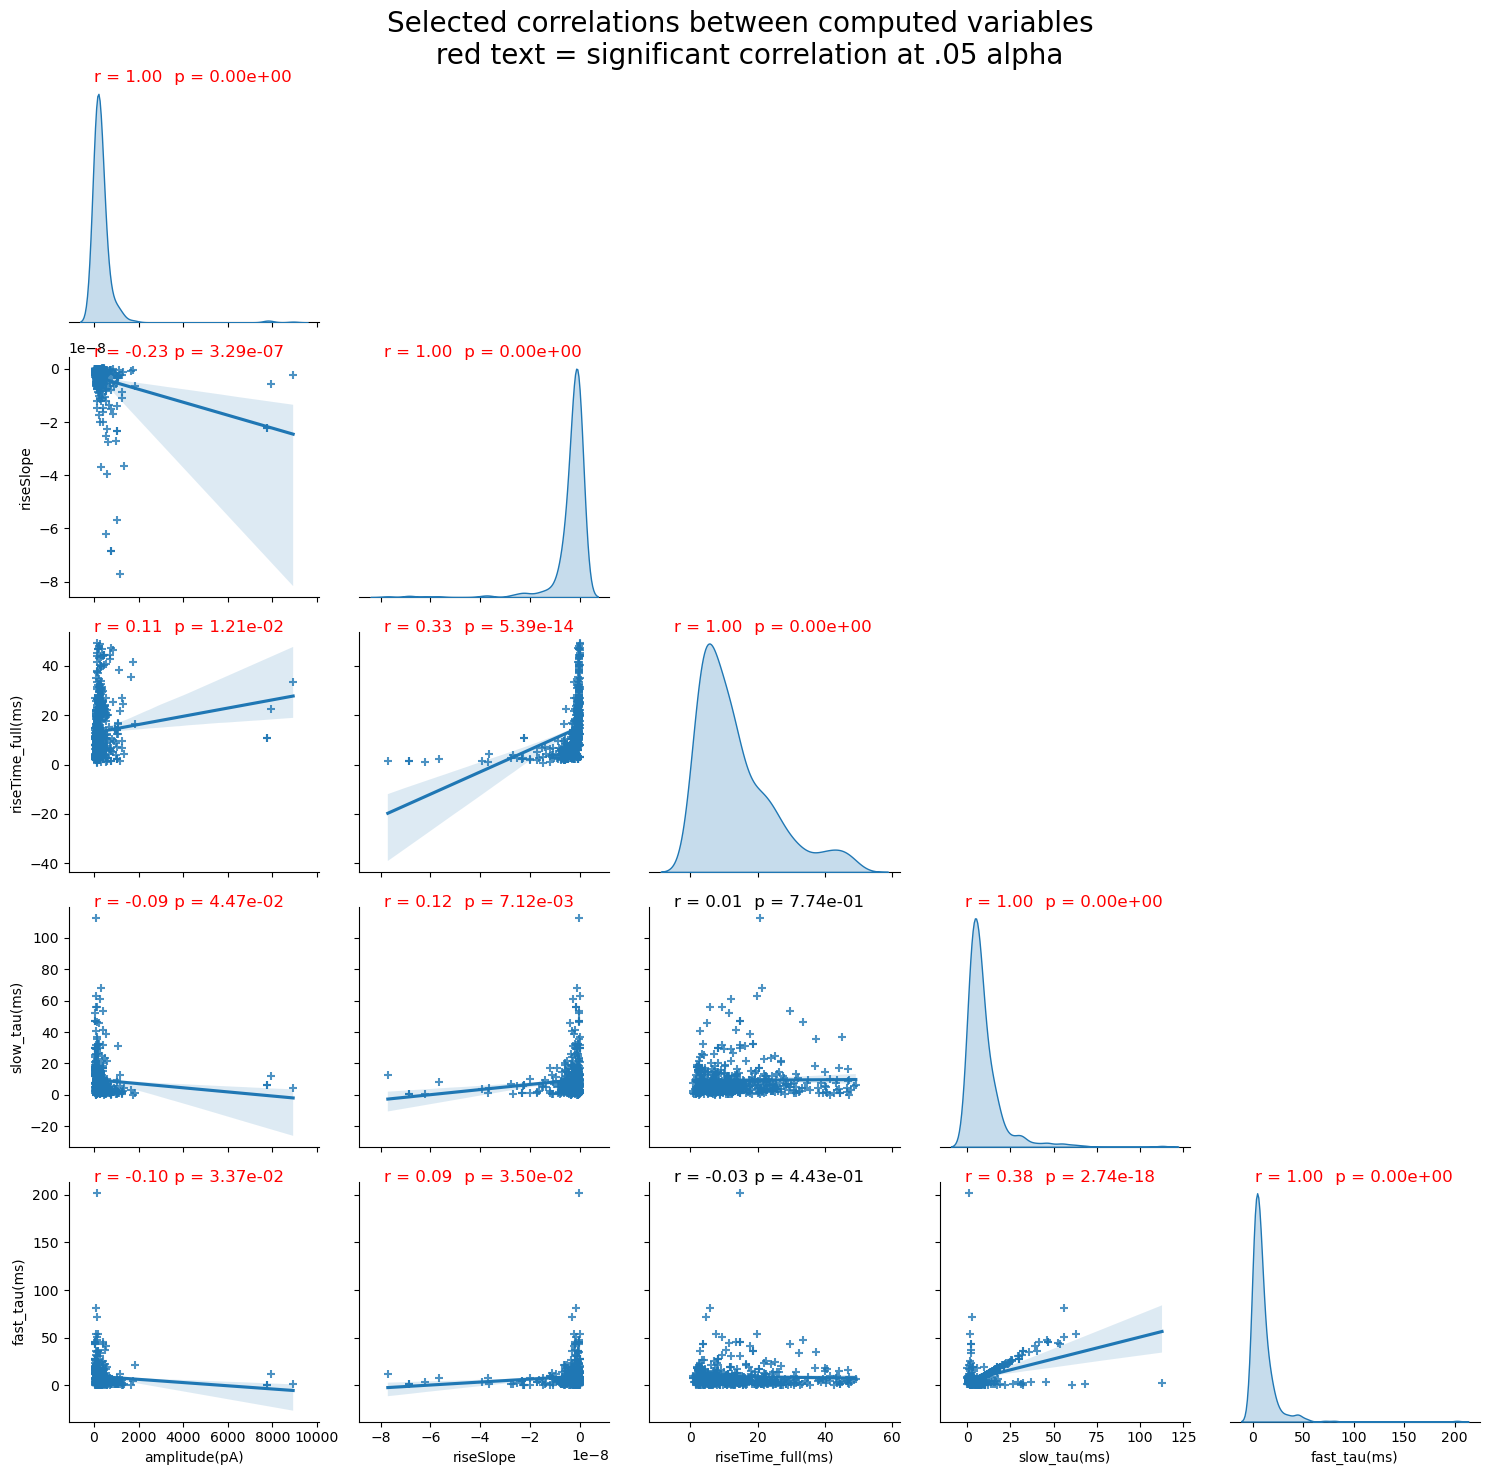

In [ ]:
# omnibus check of correlations between copmuted variables.

from scipy.stats import pearsonr

thresh = .5

def corrfunc(x, y, **kws):
    (r, p) = pearsonr(x, y)
    ax = plt.gca()
    if p <.05:
        ax.annotate("r = {:.2f} ".format(r), xy=(.1, 1), color='r', fontsize=12,xycoords=ax.transAxes)
        ax.annotate(" p = {:.2e}".format(p), xy=(.4, 1),color='r', fontsize=12,xycoords=ax.transAxes)
    else:
        ax.annotate("r = {:.2f} ".format(r), xy=(.1,1),fontsize=12,xycoords=ax.transAxes)
        ax.annotate(" p = {:.2e}".format(p), xy=(.4, 1),fontsize=12, xycoords=ax.transAxes)


graph = sns.pairplot(data=adf[adf.r2>thresh][['amplitude(pA)', 'riseSlope', 'riseTime_full(ms)',  'slow_tau(ms)', 'fast_tau(ms)']].dropna(), diag_kind='kde', kind='reg',corner=True, height=3, aspect=1, plot_kws=dict(marker="+"))
graph.map(corrfunc)
graph.fig.suptitle('Selected correlations between computed variables \n red text = significant correlation at .05 alpha', wrap=True, fontsize=20)
plt.subplots_adjust(wspace=0.2, hspace=0.2)
plt.tight_layout()
plt.show()





In [19]:
min_len = min(map(len, adf["raw_sig"]))
adf["trunc_arr"] = [x[:min_len] for x in adf["raw_sig"]]

(15404, 2)


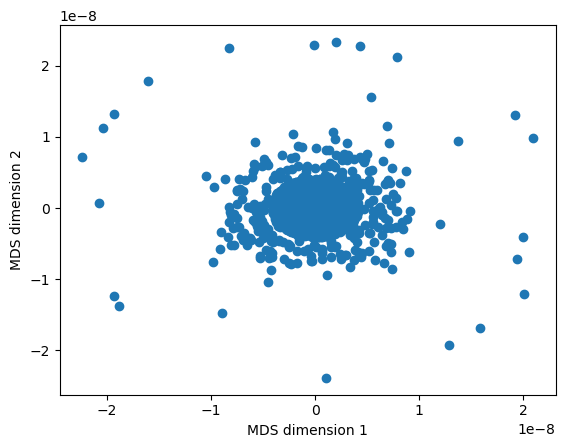

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import MDS

# multidimensional scaling for visualization in projected space. reveal potential clustering based on vector similarities and dissimilarities rather than covariance/variance


input_arr = np.stack(adf.trunc_arr)

# Your data: shape (n_samples, n_features)
X = np.asarray(input_arr)


mds = MDS(
    n_components=2,
    metric=True,
    random_state=42,
    n_init=4
)

X_2d = mds.fit_transform(X)

print(X_2d.shape)

plt.scatter(X_2d[:, 0], X_2d[:, 1])
plt.xlabel("MDS dimension 1")
plt.ylabel("MDS dimension 2")
plt.show()

(15404, 3)


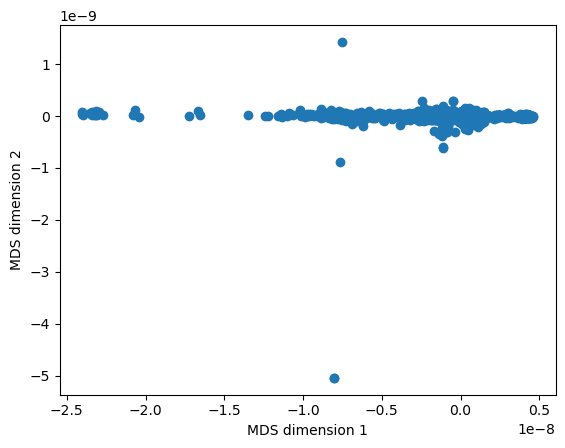

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Principal component analysis for visualization in projected space, based on covariance and rotation

input_arr = np.stack(adf.trunc_arr)

# Your data: shape (n_samples, n_features)
X = np.asarray(input_arr)


pca = PCA(
    n_components=3
)

X_2d = pca.fit_transform(X)

print(X_2d.shape)

plt.scatter(X_2d[:, 0], X_2d[:, 1])
plt.xlabel("MDS dimension 1")
plt.ylabel("MDS dimension 2")
plt.show()

# Bundle Reader code

### originally authored by Luke Campagnola, 2015

In [13]:
"""
Heka Patchmaster .dat file reader 

Structure definitions adapted from StimFit hekalib.cpp

Brief example::

    # Load a .dat file
    bundle = Bundle(file_name)
    
    # Select a trace
    trace = bundle.pul[group_ind][series_ind][sweep_ind][trace_ind]
    
    # Print meta-data for this trace
    print(trace)
    
    # Load data for this trace
    data = bundle.data[group_id, series_id, sweep_ind, trace_ind]

"""

import numpy as np
import re, struct, collections


class Struct(object):
    """High-level wrapper around struct.Struct that makes it a bit easier to 
    unpack large, nested structures.
    
    * Unpacks to dictionary allowing fields to be retrieved by name
    * Optionally massages field data on read
    * Handles arrays and nested structures
    
    *fields* must be a list of tuples like (name, format) or (name, format, function)
    where *format* must be a simple struct format string like 'i', 'd', 
    '32s', or '4d'; or another Struct instance.
    
    *function* may be either a function that filters the data for that field
    or None to exclude the field altogether.
    
    If *size* is given, then an exception will be raised if the final struct size
    does not match the given size.

    
    Example::
        
        class MyStruct(Struct):
            field_info = [
                ('char_field', 'c'),                # single char 
                ('char_array', '8c'),               # list of 8 chars
                ('str_field',  '8s', cstr),         # C string of len 8
                ('sub_struct', MyOtherStruct),      # dict generated by s2.unpack 
                ('filler', '32s', None),            # ignored field
            ]
            size_check = 300
            
        fh = open(fname, 'rb')
        data = MyStruct(fh)
    
    """
    field_info = None
    size_check = None
    _fields_parsed = None
    
    
    
    def __init__(self, data, endian='<'):
        """Read the structure from *data* and return an ordered dictionary of 
        fields.
        
        *data* may be a string or file.
        *endian* may be '<' or '>'
        """
        field_info = self._field_info()
        if not isinstance(data, (str, bytes)):
            data = data.read(self._le_struct.size)
        if endian == '<':
            items = self._le_struct.unpack(data)
        elif endian == '>':
            items = self._be_struct.unpack(data)
        else:
            raise ValueError('Invalid endian: %s' % endian)
        
        fields = collections.OrderedDict()
        
        i = 0
        for name, fmt, func in field_info:
            # pull item(s) out of the list based on format string
            if len(fmt) == 1 or fmt[-1] == 's':
                item = items[i]
                i += 1
            else:
                n = int(fmt[:-1])
                item = items[i:i+n]
                i += n
            
            # try unpacking sub-structure
            if isinstance(func, tuple):
                substr, func = func
                item = substr(item, endian)
            
            # None here means the field should be omitted
            if func is None:
                continue
            # handle custom massaging function
            if func is not True:
                item = func(item)
            fields[name] = item
            setattr(self, name, item)
            
        self.fields = fields
        
    @classmethod
    def _field_info(cls):
        if cls._fields_parsed is not None:
            return cls._fields_parsed
        
        fmt = ''
        fields = []
        for items in cls.field_info:
            if len(items) == 3:
                name, ifmt, func = items
            else:
                name, ifmt = items
                func = True
                
            if isinstance(ifmt, type) and issubclass(ifmt, Struct):
                func = (ifmt, func) # instructs to unpack with sub-struct before calling function
                ifmt = '%ds' % ifmt.size()
            elif len(ifmt) > 1 and re.match(r'\d*[xcbB?hHiIlLqQfdspP]', ifmt) is None:
                raise TypeError('Unsupported format string "%s"' % ifmt)
            
            fields.append((name, ifmt, func))
            fmt += ifmt
        cls._le_struct = struct.Struct('<' + fmt)
        cls._be_struct = struct.Struct('>' + fmt)
        cls._fields_parsed = fields
        if cls.size_check is not None:
            assert cls._le_struct.size == cls.size_check
        return fields

    @classmethod
    def size(cls):
        cls._field_info()
        return cls._le_struct.size
    
    @classmethod
    def array(cls, x):
        """Return a new StructArray class of length *x* and using this struct 
        as the array item type.
        """
        return type(cls.__name__+'[%d]'%x, (StructArray,), 
                    {'item_struct': cls, 'array_size': x})
        
    def __repr__(self, indent=0):
        indent_str = '    '*indent
        r = indent_str + '%s(\n'%self.__class__.__name__
        if not hasattr(self, 'fields'):
            r = r[:-1] + '<initializing>)'
            return r
        for k,v in self.fields.items():
            if isinstance(v, Struct):
                r += indent_str + '    %s = %s\n' % (k, v.__repr__(indent=indent+1).lstrip())
            else:
                r += indent_str + '    %s = %r\n' % (k, v)
        r += indent_str + ')'
        return r

    def get_fields(self):
        """Recursively convert struct fields+values to nested dictionaries.
        """
        fields = self.fields.copy()
        for k,v in fields.items():
            if isinstance(v, StructArray):
                fields[k] = [x.get_fields() for x in v.array]
            elif isinstance(v, Struct):
                fields[k] = v.get_fields()
        return fields

    
class StructArray(Struct):
    item_struct = None
    array_size = None
    
    def __init__(self, data, endian='<'):
        if not isinstance(data, (str, bytes)):
            data = data.read(self.size())
        items = []
        isize = self.item_struct.size()
        for i in range(self.array_size):
            d = data[:isize]
            data = data[isize:]
            items.append(self.item_struct(d, endian))
        self.array = items

    def __getitem__(self, i):
        return self.array[i]
        
    @classmethod
    def size(self):
        return self.item_struct.size() * self.array_size

    def __repr__(self, indent=0):
        r = '    '*indent + '%s(\n' % self.__class__.__name__
        for item in self.array:
            r += item.__repr__(indent=indent+1) + ',\n'
        r += '    '*indent + ')'
        return r


def cstr(byt):
    """Convert C string bytes to python string.
    """
    try:
        ind = byt.index(b'\0')
    except ValueError:
        return byt
    return byt[:ind].decode('utf-8', errors='ignore')


class BundleItem(Struct):
    field_info = [
        ('Start', 'i'),
        ('Length', 'i'),
        ('Extension', '8s', cstr),
    ]
    size_check = 16


class BundleHeader(Struct):
    field_info = [
        ('Signature', '8s', cstr),
        ('Version', '32s', cstr),
        ('Time', 'd'),
        ('Items', 'i'),
        ('IsLittleEndian', '12s'),
        ('BundleItems', BundleItem.array(12)),
    ]
    size_check = 256



class TreeNode(Struct):
    """Struct that also represents a node in a Pulse file tree.
    """
    def __init__(self, fh, pul, level=0):
        self.level = level
        self.children = []
        endian = pul.endian
        
        # The record structure in the file may differ from our expected structure
        # due to version differences, so we read the required number of bytes, and
        # then pad or truncate before unpacking the record. This will probably
        # result in corrupt data in some situations..
        realsize = pul.level_sizes[level]
        structsize = self.size()
        data = fh.read(realsize)
        diff = structsize - realsize
        if diff > 0:
            data = data + b'\0'*diff
        else:
            data = data[:structsize]
        
        # initialize struct data
        Struct.__init__(self, data, endian)
        
        # Next read the number of children
        nchild = struct.unpack(endian + 'i', fh.read(4))[0]
            
        level += 1
        if level >= len(pul.rectypes):
            return
        child_rectype = pul.rectypes[level]
        for i in range(nchild):
            self.children.append(child_rectype(fh, pul, level))

    def __getitem__(self, i):
        return self.children[i]
    
    def __len__(self):
        return len(self.children)
    
    def __iter__(self):
        return self.children.__iter__()
    
    def __repr__(self, indent=0):
        # Return a string describing this structure
        ind = '    '*indent
        srep = Struct.__repr__(self, indent)[:-1]  # exclude final parenthese
        srep += ind + '    children = %d,\n' % len(self)
        #srep += ind + 'children = [\n'
        #for ch in self:
            #srep += ch.__repr__(indent=indent+1) + ',\n'
        srep += ind + ')'
        return srep




class TraceRecord(TreeNode):
    field_info = [
        ('Mark', 'i'),
        ('Label', '32s', cstr),
        ('TraceCount', 'i'),
        ('Data', 'i'),
        ('DataPoints', 'i'),
        ('InternalSolution', 'i'),
        ('AverageCount', 'i'),
        ('LeakCount', 'i'),
        ('LeakTraces', 'i'),
        ('DataKind', 'h'),
        ('Filler1', 'h', None),
        ('RecordingMode', 'c'),
        ('AmplIndex', 'c'),
        ('DataFormat', 'c'),
        ('DataAbscissa', 'c'),
        ('DataScaler', 'd'),
        ('TimeOffset', 'd'),
        ('ZeroData', 'd'),
        ('YUnit', '8s', cstr),
        ('XInterval', 'd'),
        ('XStart', 'd'),
        ('XUnit', '8s', cstr),
        ('YRange', 'd'),
        ('YOffset', 'd'),
        ('Bandwidth', 'd'),
        ('PipetteResistance', 'd'),
        ('CellPotential', 'd'),
        ('SealResistance', 'd'),
        ('CSlow', 'd'),
        ('GSeries', 'd'),
        ('RsValue', 'd'),
        ('GLeak', 'd'),
        ('MConductance', 'd'),
        ('LinkDAChannel', 'i'),
        ('ValidYrange', 'c'),
        ('AdcMode', 'c'),
        ('AdcChannel', 'h'),
        ('Ymin', 'd'),
        ('Ymax', 'd'),
        ('SourceChannel', 'i'),
        ('ExternalSolution', 'i'),
        ('CM', 'd'),
        ('GM', 'd'),
        ('Phase', 'd'),
        ('DataCRC', 'i'),
        ('CRC', 'i'),
        ('GS', 'd'),
        ('SelfChannel', 'i'),
        ('Filler2', 'i', None),
    ]
    size_check = 296


class SweepRecord(TreeNode):
    field_info = [
        ('Mark', 'i'),
        ('Label', '32s', cstr),
        ('AuxDataFileOffset', 'i'),
        ('StimCount', 'i'),
        ('SweepCount', 'i'),
        ('Time', 'd'),
        ('Timer', 'd'),
        ('SwUserParams', '4d'),
        ('Temperature', 'd'),
        ('OldIntSol', 'i'),
        ('OldExtSol', 'i'),
        ('DigitalIn', 'h'),
        ('SweepKind', 'h'),
        ('Filler1', 'i', None),
        ('Markers', '4d'),
        ('Filler2', 'i', None),
        ('CRC', 'i'),
    ]
    size_check = 160


class UserParamDescrType(Struct):
    field_info = [
        ('Name', '32s', cstr),
        ('Unit', '8s', cstr),
    ]
    size_check = 40


class AmplifierState(Struct):
    field_info = [
        ('StateVersion', '8s', cstr),
        ('RealCurrentGain', 'd'),
        ('RealF2Bandwidth', 'd'),
        ('F2Frequency', 'd'),
        ('RsValue', 'd'),
        ('RsFraction', 'd'),
        ('GLeak', 'd'),
        ('CFastAmp1', 'd'),
        ('CFastAmp2', 'd'),
        ('CFastTau', 'd'),
        ('CSlow', 'd'),
        ('GSeries', 'd'),
        ('StimDacScale', 'd'),
        ('CCStimScale', 'd'),
        ('VHold', 'd'),
        ('LastVHold', 'd'),
        ('VpOffset', 'd'),
        ('VLiquidJunction', 'd'),
        ('CCIHold', 'd'),
        ('CSlowStimVolts', 'd'),
        ('CCTrackVHold', 'd'),
        ('TimeoutLength', 'd'),
        ('SearchDelay', 'd'),
        ('MConductance', 'd'),
        ('MCapacitance', 'd'),
        ('SerialNumber', '8s', cstr),
        ('E9Boards', 'h'),
        ('CSlowCycles', 'h'),
        ('IMonAdc', 'h'),
        ('VMonAdc', 'h'),
        ('MuxAdc', 'h'),
        ('TstDac', 'h'),
        ('StimDac', 'h'),
        ('StimDacOffset', 'h'),
        ('MaxDigitalBit', 'h'),
        ('SpareInt1', 'h', None),
        ('SpareInt2', 'h', None),
        ('SpareInt3', 'h', None),

        ('AmplKind', 'c'),
        ('IsEpc9N', 'c'),
        ('ADBoard', 'c'),
        ('BoardVersion', 'c'),
        ('ActiveE9Board', 'c'),
        ('Mode', 'c'),
        ('Range', 'c'),
        ('F2Response', 'c'),

        ('RsOn', 'c'),
        ('CSlowRange', 'c'),
        ('CCRange', 'c'),
        ('CCGain', 'c'),
        ('CSlowToTstDac', 'c'),
        ('StimPath', 'c'),
        ('CCTrackTau', 'c'),
        ('WasClipping', 'c'),

        ('RepetitiveCSlow', 'c'),
        ('LastCSlowRange', 'c'),
        ('Locked', 'c'),
        ('CanCCFast', 'c'),
        ('CanLowCCRange', 'c'),
        ('CanHighCCRange', 'c'),
        ('CanCCTracking', 'c'),
        ('HasVmonPath', 'c'),

        ('HasNewCCMode', 'c'),
        ('Selector', 'c'),
        ('HoldInverted', 'c'),
        ('AutoCFast', 'c'),
        ('AutoCSlow', 'c'),
        ('HasVmonX100', 'c'),
        ('TestDacOn', 'c'),
        ('QMuxAdcOn', 'c'),

        ('RealImon1Bandwidth', 'd'),
        ('StimScale', 'd'),

        ('Gain', 'c'),
        ('Filter1', 'c'),
        ('StimFilterOn', 'c'),
        ('RsSlow', 'c'),
        ('Old1', 'c'),
        ('CCCFastOn', 'c'),
        ('CCFastSpeed', 'c'),
        ('F2Source', 'c'),

        ('TestRange', 'c'),
        ('TestDacPath', 'c'),
        ('MuxChannel', 'c'),
        ('MuxGain64', 'c'),
        ('VmonX100', 'c'),
        ('IsQuadro', 'c'),
        ('SpareBool4', 'c', None),
        ('SpareBool5', 'c', None),

        ('StimFilterHz', 'd'),
        ('RsTau', 'd'),
        ('FilterOffsetDac', 'h'),
        ('ReferenceDac', 'h'),
        ('SpareInt6', 'h', None),
        ('SpareInt7', 'h', None),
        ('Spares1', '24s', None),
        
        ('CalibDate', '16s'),
        ('SelHold', 'd'),
        ('Spares2', '32s', None),
    ]
    size_check = 400
    
    
class LockInParams(Struct):
    field_info = [
        ('ExtCalPhase', 'd'),
        ('ExtCalAtten', 'd'),
        ('PLPhase', 'd'),
        ('PLPhaseY1', 'd'),
        ('PLPhaseY2', 'd'),
        ('UsedPhaseShift', 'd'),
        ('UsedAttenuation', 'd'),
        ('Spares2', '8s', None),
        ('ExtCalValid', '?'),
        ('PLPhaseValid', '?'),
        ('LockInMode', 'c'),
        ('CalMode', 'c'),
        ('Spares', '28s', None),
    ]
    size_check = 96


class SeriesRecord(TreeNode):
    field_info = [
        ('Mark', 'i'),
        ('Label', '32s', cstr),
        ('Comment', '80s', cstr),
        ('SeriesCount', 'i'),
        ('NumberSweeps', 'i'),
        ('AmplStateOffset', 'i'),
        ('AmplStateSeries', 'i'),
        ('riesType', 'c'),
        ('Filler1', 'c', None),
        ('Filler2', 'c', None),
        ('Filler3', 'c', None),
        ('Time', 'd'),
        ('PageWidth', 'd'),
        ('SwUserParamDescr', UserParamDescrType.array(4)),
        ('Filler4', '32s', None),
        ('SeUserParams', '4d'),
        ('LockInParams', LockInParams),
        ('AmplifierState', AmplifierState),
        ('Username', '80s', cstr),
        ('UserParamDescr', UserParamDescrType.array(4)),
        ('Filler5', 'i', None),
        ('CRC', 'i'),
    ]
    size_check = 1120


class GroupRecord(TreeNode):
    field_info = [
        ('Mark', 'i'),
        ('Label', '32s', cstr),
        ('Text', '80s', cstr),
        ('ExperimentNumber', 'i'),
        ('GroupCount', 'i'),
        ('CRC', 'i'),
    ]
    size_check = 128


class Pulsed(TreeNode):
    field_info = [
        ('Version', 'i'),
        ('Mark', 'i'),
        ('VersionName', '32s', cstr),
        ('AuxFileName', '80s', cstr),
        ('RootText', '400s', cstr),
        ('StartTime', 'd'),
        ('MaxSamples', 'i'),
        ('CRC', 'i'),
        ('Features', 'h'),
        ('Filler1', 'h', None),
        ('Filler2', 'i', None),
    ]
    size_check = 544
    
    rectypes = [
        None,
        GroupRecord,
        SeriesRecord,
        SweepRecord,
        TraceRecord
    ]
    
    def __init__(self, bundle, offset=0, size=None):
        fh = open(bundle.file_name, 'rb')
        fh.seek(offset)
        
        # read .pul header
        magic = fh.read(4) 
        if magic == b'eerT':
            self.endian = '<'
        elif magic == b'Tree':
            self.endian = '>'
        else:
            raise RuntimeError('Bad file magic: %s' % magic)
        
        levels = struct.unpack(self.endian + 'i', fh.read(4))[0]

        # read size of each level (one int per level)
        self.level_sizes = []
        for i in range(levels):
            size = struct.unpack(self.endian + 'i', fh.read(4))[0]
            self.level_sizes.append(size)
            
        TreeNode.__init__(self, fh, self)


class Data(object):
    def __init__(self, bundle, offset=0, size=None):
        self.bundle = bundle
        self.offset = offset
        
    def __getitem__(self, *args):
        index = args[0]
        assert len(index) == 4
        pul = self.bundle.pul
        trace = pul[index[0]][index[1]][index[2]][index[3]]
        fh = open(self.bundle.file_name, 'rb')
        fh.seek(trace.Data)
        fmt = bytearray(trace.DataFormat)[0]
        dtype = [np.int16, np.int32, np.float16, np.float32][fmt]
        data = np.fromfile(fh, count=trace.DataPoints, dtype=dtype)
        return data * trace.DataScaler + trace.ZeroData


class Bundle(object):
    
    item_classes = {
        '.pul': Pulsed,
        '.dat': Data,
    }
    
    def __init__(self, file_name):
        self.file_name = file_name
        fh = open(file_name, 'rb')
        
        # Read header assuming little endiam
        endian = '<'
        self.header = BundleHeader(fh, endian)

        # If the header is bad, re-read using big endian
        if self.header.IsLittleEndian[0] == b'\0':
            endian = '>'
            fh.seek(0)
            self.header = BundleHeader(fh, endian)
            
        # Read bundle items
        #self.bundle_items = [Struct(fh, endian + bundle_item[0], bundle_item[1]) for i in range(12)]

        # catalog extensions of bundled items
        self.catalog = {}
        for item in self.header.BundleItems:
            item.instance = None
            ext = item.Extension
            self.catalog[ext] = item
            
        fh.close()

    @property
    def pul(self):
        """The Pulsed object from this bundle.
        """
        return self._get_item_instance('.pul')
    
    @property
    def data(self):
        """The Data object from this bundle.
        """
        return self._get_item_instance('.dat')
        
    def _get_item_instance(self, ext):
        if ext not in self.catalog:
            return None
        item = self.catalog[ext]
        if item.instance is None:
            cls = self.item_classes[ext]
            item.instance = cls(self, item.Start, item.Length)
        return item.instance
        
    def __repr__(self):
        return "Bundle(%r)" % list(self.catalog.keys())